# 299. Searching a whole gene catalog for a protein with sourmash sketches: OM-RGC v2 pilot, sourmash vs DIAMOND

**Question.** Board idea 12 is to search every sequencing run for a protein pattern with
hashed reduced-alphabet sketches. A sketch here is sourmash's FracMinHash: it keeps only
the k-mers whose hash falls below a cut-off, one in `scaled` on average, so a 300-residue
protein keeps about 3 k-mers at scaled 100 and none to one at scaled 1000. This notebook
runs the smallest test that could kill the idea, on one ocean gene catalog, OM-RGC v2,
before anyone tries it on all of the Sequence Read Archive.

**Decision this informs.** Whether to spend more time on board idea 12 with sourmash
sketches as the index. If no setting passes, searching every run for a protein needs a
different index (for example kmerseek's own, which keeps every k-mer), not this one.

**Query and target.** Queries: 100 arctic clam proteins drawn at random (seed 299) from
`Glanz_Clam_AllModels.proteins.fasta` (69_055 proteins) and 9 regions of BHF (*Botryllus*
histocompatibility factor) copied from
[PR 80](https://github.com/seanome/2024-kmerseek-analysis/pull/80)'s table, plus 20 dipeptide-shuffled copies of each (same length,
same count of every adjacent residue pair). Target database: OM-RGC v2 (46.8 million genes
per the Ocean Gene Atlas v2.0 paper; recounted on Sherlock).
Comparator: DIAMOND blastp 2.2.8 `--very-sensitive` on the same genes translated in frame 1,
on the same Sherlock partition and thread count.

**Rules, fixed 2026-10-18 before any run** (full text: `notebooks/299_data/rules.md`):

1. Step 1 is dead if sketching the whole catalog with `sourmash sketch translate`, all nine
   alphabet and k settings at one scaled value, needs more than 1_536 CPU-hours (two days of a 32-CPU node) at both scaled
   100 and 1000 (arithmetic from a 1 GB slice, one CPU).
2. Step 3 passes if some setting finds at least 80% of DIAMOND's (real query, gene) pairs at
   E < 1e-5 while each shuffled copy hits fewer than 1% as many genes as a real query does.
   Higher recall is good; a lower shuffled-hit rate is good.

**Status on 2026-10-18.** Queries, rules and the Sherlock jobs are ready. One command,
`bash notebooks/299_submit_all.sh`, submits every job with SLURM dependencies (setup, step 1,
then a job that reads step 1's verdict and, only if the catalog fits, submits DIAMOND, the
sketching, the searches and the scoring). No Sherlock job
has run yet, so steps 1 to 4 have no result. Sections below fill in as each job finishes.

**Facts read 2026-10-18** (`notebooks/299_data/sources_read_2026-10-18.tsv`):

| What | Value | Source |
|---|---|---|
| OM-RGC v2 record | BioStudies S-BSST297, "Ocean Microbial Reference Gene Catalog v2 (OM-RGC.v2)", released 2019-11-12 | https://www.ebi.ac.uk/biostudies/files/S-BSST297/S-BSST297.json |
| OM-RGC v2 gene sequences file | OM-RGC_v2_genes.fna.gz, 29607178264 bytes (gzipped DNA FASTA); no protein file in the record | https://ftp.ebi.ac.uk/biostudies/fire/S-BSST/S-BSSTxxx297/S-BSST297/Files/OM-RGC_v2_genes.fna.gz (HTTP Content-Length) |
| OM-RGC v2 README | last change 07 March 2019; no gene count given | https://ftp.ebi.ac.uk/biostudies/fire/S-BSST/S-BSSTxxx297/S-BSST297/Files/_README |
| OM-RGC v2 gene count | 46.8 million non-redundant genes (Ocean Gene Atlas v2.0); counted again on Sherlock by the setup job | https://academic.oup.com/nar/article/50/W1/W516/6605321 (via search summary) |
| OM-RGC v2 md5 | not found | BioStudies listing gives sizes only |
| OM-RGC v1 (not used) | OM-RGC_seq.release.tsv.gz, 7.8 GB, 40154822 genes | https://ocean-microbiome.embl.de/companion.html |
| Logan proteins | 109.4 billion "other-complete" proteins clustered into 3.0 billion non-redundant sequences; 445.3 billion sequences in all three subsets | https://pmc.ncbi.nlm.nih.gov/articles/PMC12424806/ (bioRxiv 2024.07.30.605881 v2, 2025-09-01, not peer reviewed) |
| Logan contigs | 0.9 petabases of contigs from 44.1 petabases of raw reads; 27.3 million accessions assembled into unitigs | https://pmc.ncbi.nlm.nih.gov/articles/PMC12424806/ |
| Logan mean protein length | not found | - |
| DIAMOND version | 2.2.8 (2026-09-20) | https://github.com/bbuchfink/diamond/releases/tag/v2.2.8 |
| sourmash version | 4.9.4 (2025-08-07) | https://pypi.org/project/sourmash/ |
| sourmash_plugin_branchwater version | 0.9.15 (2026-04-26) | https://pypi.org/project/sourmash_plugin_branchwater/ |
| seqkit version | 2.14.0 (2026-09-24) | https://github.com/shenwei356/seqkit/releases/tag/v2.14.0 |
| micromamba version | 2.9.0-0 (2026-08-07) | https://github.com/mamba-org/micromamba-releases/releases |
| Sherlock glibc | 2.17 (sourmash 4.9.4's Linux wheel needs 2.28, so the conda-forge/bioconda build is used) | ldd --version on sh03-ln06 |
| sourmash team | C. Titus Brown, Luiz Irber, N. Tessa Pierce-Ward listed as the sourmash team; branchwater credited to UC Davis Data Intensive Biology lab, USDA-ARS and JGI | https://branchwater.jgi.doe.gov/contact and /about (via search summary) |
| Logan lead | Lead: Rayan Chikhi, "co-Lead: Artem Babaian" | https://github.com/IndexThePlanet/Logan |
| Babaian role | assistant professor, Donnelly Centre, University of Toronto | https://aws.amazon.com/fr/solutions/case-studies/canadas-ai-innovators/logan/ (via search summary) |
| Basecamp Research | London company mining environmental samples for proteins; Glen Gowers described as CEO and co-founder (June 2025 announcement) | https://astrobiology.com/2025/06/11/basecamp-research-announces-breakthrough-discovery-of-over-one-million-new-species/ (via search summary) |
| OM-RGC v2 gene table (the file used) | OM-RGC_v2.tsv.gz, 10320406416 bytes; 14 columns with a header row, column 14 = gene DNA; passed gzip's full check (job 48546051) | https://ftp.ebi.ac.uk/biostudies/fire/S-BSST/S-BSSTxxx297/S-BSST297/Files/OM-RGC_v2.tsv.gz |
| OM-RGC v2 genes FASTA (not used) | two downloads of OM-RGC_v2_genes.fna.gz (jobs 48522928, 48546051) differed at byte 3621226795; the first failed gzip's check | same record |

In [1]:
import importlib.util
import json
import sys
from pathlib import Path

import polars as pl
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "notebooks" / "299_data"
TABLES = ROOT / "tables"
FIGURES = ROOT / "figures"
sys.path.insert(0, str(ROOT / "notebooks"))
spec = importlib.util.spec_from_file_location(
    "pilot", ROOT / "notebooks" / "299_omrgc_sketch_pilot.py"
)
pilot = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pilot)
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
_ = pl.Config.set_fmt_str_lengths(60)

## 0. The queries

109 real queries and 2_180 shuffled copies (`notebooks/299_data/queries.tsv`). The BHF
regions are, for each gene in BHF's Figure 1 draft, the BHF stretch with the lowest kmerseek
E-value over notebook 241's alphabet and k values (0-based start, end not included). The
TSHZ1 region is 11 residues long, shorter than k = 13, so at k = 13 it has no k-mer and
cannot hit anything; the TSHZ2 region (14 residues) holds two 13-mers.

Figure: query length, one dot per real query, BHF regions and clam proteins in two colours,
with the three k values as dashed lines. A query shorter than k has no k-mer to keep.

shape: (2, 5)
┌────────────┬─────────┬─────────┬────────────┬─────────┐
│ kind       ┆ queries ┆ min_len ┆ median_len ┆ max_len │
│ ---        ┆ ---     ┆ ---     ┆ ---        ┆ ---     │
│ str        ┆ u32     ┆ i64     ┆ f64        ┆ i64     │
╞════════════╪═════════╪═════════╪════════════╪═════════╡
│ bhf_region ┆ 9       ┆ 11      ┆ 39.0       ┆ 91      │
│ clam       ┆ 100     ┆ 69      ┆ 261.0      ┆ 1556    │
└────────────┴─────────┴─────────┴────────────┴─────────┘
shape: (9, 8)
┌────────────┬──────────┬────────────┬────────────┬────────────┬───────────┬───────────┬───────────┐
│ query_id   ┆ gene     ┆ kmerseek_a ┆ kmerseek_k ┆ bhf_start_ ┆ bhf_end_e ┆ kmerseek_ ┆ sequence  │
│ ---        ┆ ---      ┆ lphabet    ┆ size       ┆ 0based     ┆ xclusive  ┆ region_ev ┆ ---       │
│ str        ┆ str      ┆ ---        ┆ ---        ┆ ---        ┆ ---       ┆ alue      ┆ str       │
│            ┆          ┆ str        ┆ i64        ┆ i64        ┆ i64       ┆ ---       ┆           │
│  

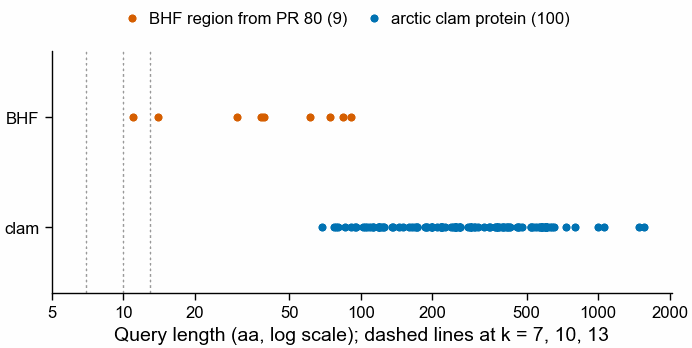

In [2]:
import pubfig as pf

queries = pl.read_csv(DATA / "queries.tsv", separator="\t")
real = queries.filter(~pl.col("shuffled"))
bhf = pl.read_csv(DATA / "bhf_regions_from_pr80.tsv", separator="\t")
print(
    real.group_by("kind").agg(
        pl.len().alias("queries"),
        pl.col("length").min().alias("min_len"),
        pl.col("length").median().alias("median_len"),
        pl.col("length").max().alias("max_len"),
    )
)
print(
    bhf.select(
        "query_id",
        "gene",
        "kmerseek_alphabet",
        "kmerseek_ksize",
        "bhf_start_0based",
        "bhf_end_exclusive",
        "kmerseek_region_evalue",
        "sequence",
    )
)
pf.use_style()
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 45)
colour = {"clam": pf.OKABE_ITO["blue"], "bhf_region": pf.OKABE_ITO["vermillion"]}
label = {"clam": "arctic clam protein (100)", "bhf_region": "BHF region from PR 80 (9)"}
for kind, sub in real.sort("length").group_by("kind", maintain_order=True):
    ax.scatter(
        sub["length"],
        [0.0 if kind[0] == "clam" else 1.0] * sub.height,
        s=6,
        color=colour[kind[0]],
        label=label[kind[0]],
    )
for k in pilot.KSIZES:
    ax.axvline(k, color=pf.GREY, linestyle=(0, (2, 2)), linewidth=0.5)
ax.set_xscale("log")
ax.set_xticks(
    [5, 10, 20, 50, 100, 200, 500, 1000, 2000],
    ["5", "10", "20", "50", "100", "200", "500", "1000", "2000"],
)
ax.minorticks_off()
ax.set_yticks([0, 1], ["clam", "BHF"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Query length (aa, log scale); dashed lines at k = 7, 10, 13")
pf.shared_legend(fig)
pf.save(fig, str(FIGURES / "299_query_lengths_clam_and_bhf_regions"))

## 1. Step 1: does sketching the whole catalog fit in two compute days?

`sourmash sketch translate` (sourmash 4.9.4) on one CPU on the catalog's first 1 GB
(1_372_957 genes), for each of 18 settings: alphabet protein, dayhoff or hp; k = 7, 10 or 13
amino acids; scaled 100 or 1000. The whole-catalog numbers are arithmetic (rate per GB times
the catalog's 32.6 GB of DNA), not measured. The rule's budget is 1_536 CPU-hours for all
nine settings of one scaled value together (two days of a 32-CPU node, set by Olga on
2026-10-19).

**Run 1 (jobs 48551687, 2026-10-19/20): dead under the rule, but the verdict measures a file
format, not sketching.** Eight settings finished in 28 to 61 minutes. The other ten (all nine
at scaled 1000, and hp k = 7 at scaled 100) ran at 98% CPU until the 40_000 s limit, so they
count as at least 362 CPU-hours each. At scaled 100 the eight that finished add up to
179 CPU-hours; with hp k = 7's lower bound the total is at least 541, under 1_536, so the
rule cannot say whether scaled 100 fits and counts it as not fitting. At scaled 1000 the
lower bounds alone reach 3_260 CPU-hours.

Why they were slow: the job wrote sketches straight to sourmash's `.zip` format, whose writer
slows down with every sketch identical to an earlier one. At scaled 1000 most genes keep no
hash, and all empty sketches are identical. On 20_000 catalog genes at protein k = 7,
scaled 1000, writing `.zip` took 132 s and writing `.sig.gz` 2.5 s; 7_856 of the 20_000
sketches were empty. A gene with no hash cannot share a hash with a query, so dropping empty
sketches changes no hit (same 25 manysearch hits with and without them).

**Run 2 (not yet run):** the same rule and budget, timing sketching to `.sig.gz` plus writing
the `.zip` index of the non-empty sketches. Figure: total CPU-hours per scaled value for each
run, the nine settings stacked; an open segment stopped at the time limit (a lower bound);
the dashed line is the budget.

run 2: .sig.gz, then non-empty .zip has not run yet
run 1: .zip written directly
shape: (18, 5)
┌───────────────────┬──────────┬─────────────┬──────────────────────────────┬────────────────┐
│ setting           ┆ finished ┆ slice_cpu_s ┆ catalog_cpu_hours_arithmetic ┆ is_lower_bound │
│ ---               ┆ ---      ┆ ---         ┆ ---                          ┆ ---            │
│ str               ┆ bool     ┆ f64         ┆ f64                          ┆ bool           │
╞═══════════════════╪══════════╪═════════════╪══════════════════════════════╪════════════════╡
│ protein.k7.s100   ┆ true     ┆ 1705.75     ┆ 15.44451                     ┆ false          │
│ protein.k10.s100  ┆ true     ┆ 2078.49     ┆ 18.81944                     ┆ false          │
│ protein.k13.s100  ┆ true     ┆ 2627.04     ┆ 23.78622                     ┆ false          │
│ dayhoff.k7.s100   ┆ true     ┆ 1982.97     ┆ 17.954565                    ┆ false          │
│ dayhoff.k10.s100  ┆ true     ┆ 2101.47     ┆ 19

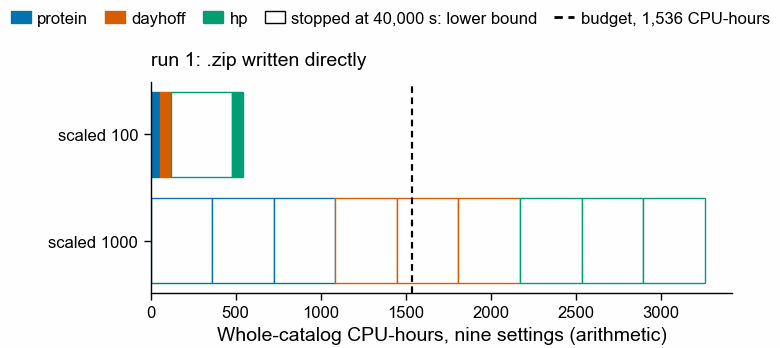

In [3]:
def step1_panel(ax, table, title):
    colour = {
        "protein": pf.OKABE_ITO["blue"],
        "dayhoff": pf.OKABE_ITO["vermillion"],
        "hp": pf.OKABE_ITO["bluish_green"],
    }
    for row_y, scaled in enumerate(pilot.SCALEDS):
        left = 0.0
        for r in table.filter(pl.col("scaled") == scaled).iter_rows(named=True):
            c = colour[r["alphabet"]]
            ax.barh(
                row_y,
                r["catalog_cpu_hours_arithmetic"],
                left=left,
                color="white" if r["is_lower_bound"] else c,
                edgecolor=c,
                linewidth=0.5,
            )
            left += r["catalog_cpu_hours_arithmetic"]
    ax.axvline(
        pilot.COMPUTE_BUDGET_CPU_HOURS,
        color="black",
        linestyle=(0, (3, 2)),
        linewidth=0.8,
    )
    ax.set_yticks(range(len(pilot.SCALEDS)), [f"scaled {s}" for s in pilot.SCALEDS])
    ax.invert_yaxis()
    ax.set_xlabel("Whole-catalog CPU-hours, nine settings (arithmetic)")
    ax.set_title(title, loc="left")


runs = [
    (
        "run 1: .zip written directly",
        TABLES / "299_step1_run1_sketch_translate_timing_1gb_slice_omrgc_v2.csv",
    ),
    (
        "run 2: .sig.gz, then non-empty .zip",
        TABLES / "299_step1_sketch_translate_timing_1gb_slice_omrgc_v2.csv",
    ),
]
present = [(t, p) for t, p in runs if p.exists()]
for t, p in runs:
    if not p.exists():
        print(t, "has not run yet")
if present:
    import matplotlib.lines as mlines
    import matplotlib.patches as mpatches

    pf.use_style()
    fig, axs = pf.figure(
        pf.TWO_COLUMN_MM if len(present) == 2 else pf.ONE_COLUMN_MM,
        45,
        ncols=len(present),
        squeeze=False,
    )
    for ax, (title, path) in zip(axs[0], present):
        table = pl.read_csv(path)
        print(title)
        print(
            table.select(
                "setting",
                "finished",
                "slice_cpu_s",
                "catalog_cpu_hours_arithmetic",
                "is_lower_bound",
            )
        )
        print(
            table.group_by("scaled")
            .agg(
                pl.col("catalog_cpu_hours_arithmetic")
                .sum()
                .alias("cpu_hours_nine_settings"),
                pl.col("is_lower_bound").sum().alias("settings_stopped_at_limit"),
            )
            .sort("scaled")
        )
        step1_panel(ax, table, title)
    handles = [
        mpatches.Patch(color=c, label=a)
        for a, c in {
            "protein": pf.OKABE_ITO["blue"],
            "dayhoff": pf.OKABE_ITO["vermillion"],
            "hp": pf.OKABE_ITO["bluish_green"],
        }.items()
    ]
    handles += [
        mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            label="stopped at 40,000 s: lower bound",
        ),
        mlines.Line2D(
            [],
            [],
            color="black",
            linestyle=(0, (3, 2)),
            label="budget, 1,536 CPU-hours",
        ),
    ]
    fig.legend(handles=handles, loc="outside upper center", ncol=5, frameon=False)
    pf.save(fig, str(FIGURES / "299_step1_catalog_cpu_hours_per_scaled_omrgc_v2"))

## 2. Step 2: DIAMOND, the comparator

DIAMOND blastp 2.2.8 of all 2_289 queries (real and shuffled) against the OM-RGC v2 genes
translated in frame 1 with genetic code 11 (seqkit 2.14.0 `translate -T 11 -f 1 --trim`).
Every hit with E <= 1e-3 is kept with its alignment coordinates; a true hit is E < 1e-5.
Command line, as `notebooks/299_step2_diamond.sbatch` runs it (paths under
`$SCRATCH/299-omrgc-pilot/diamond`):

```
diamond makedb --threads 32 --in OM-RGC_v2_proteins.faa -d omrgc_v2
diamond blastp --threads 32 --very-sensitive --evalue 1e-3 --max-target-seqs 0 \
    --block-size 4 --index-chunks 4 --query queries.faa --db omrgc_v2.dmnd --out hits.tsv \
    --outfmt 6 qseqid sseqid pident length qstart qend sstart send evalue bitscore qlen slen
```

The job also writes the exact command it ran to `299_data/sherlock/blastp_command.txt`.

In [4]:
cmd_path = DATA / "sherlock" / "blastp_command.txt"
if not cmd_path.exists():
    print("Step 2 has not run yet: no", cmd_path)
else:
    print(cmd_path.read_text())

Step 2 has not run yet: no /Users/olga/code/2024-kmerseek-analysis-299/notebooks/299_data/sherlock/blastp_command.txt


## 3. Step 3: the kill test

For each of the 18 settings, `sourmash scripts manysearch` (branchwater plugin 0.9.15) of
all 2_289 queries against the sketched catalog. A sourmash hit is a (query, gene) pair that
shares at least one hash. Recall is the share of DIAMOND's real-query pairs at E < 1e-5 that
sourmash also hits, computed exactly by searching against only the genes DIAMOND hit. The
shuffled-hit rate is the genes hit by all shuffled copies divided by 20 times the genes hit
by the real queries. When a setting would write more than 2 billion hit rows on the full
catalog (low-k hp: almost every query shares a hash with almost every gene), its counts come
from a fixed 1% random sample of genes; the figure rings those points.

Figure: x = recall, y = shuffled-hit rate (log scale, 0 on its own line), one mark per
setting; colour = alphabet, shape = k, filled = scaled 100, open = scaled 1000; the star is
DIAMOND at its own measured shuffled rate. The grey box is the pass region.

In [5]:
verdict_path = DATA / "verdict.json"
if not verdict_path.exists():
    print("Step 3 has not run yet: no", verdict_path.name)
else:
    verdict = json.loads(verdict_path.read_text())
    table = pl.read_csv(TABLES / "299_kill_test_recall_vs_shuffled_rate_omrgc_v2.csv")
    print(
        table.select(
            "setting",
            "count_source",
            "recall",
            "shuffled_rate",
            "real_hits",
            "shuffled_hits",
            "real_queries_with_no_hash",
            "wall_s",
            "cpu_s",
            "max_rss_gb",
            "passes",
        )
    )
    print(verdict["result"], verdict["passing_settings"])
    pilot.plot_kill_test(table)

Step 3 has not run yet: no verdict.json


## 4. Step 4: where on the query the shared k-mers sit (only if step 3 passes)

Not built. It runs only for a setting that passes step 3: kmerseek's run statistics on the
same hits, and whether its region E-value separates DIAMOND's hits from the shuffled copies'
hits better than sourmash containment alone.

## 5. Step 5: what it would cost for Logan's proteins

Logan's preprint (bioRxiv 2024.07.30.605881, version 2 of 2025-09-01, not peer reviewed)
reports 109.4 billion proteins in its "other-complete" set, clustered to 3.0 billion
non-redundant sequences, and 445.3 billion sequences over all three sets. The number on the
Session 3 doc, 109 billion, matches the first. The cost below scales step 1's per-gene rate;
it is an upper bound per protein, since Logan's proteins need no six-frame translation.

From step 1 run 1, whose scaled 1000 times are lower bounds inflated by the .zip writer:
shape: (2, 3)
┌────────┬─────────────────────────┬────────────────────────────┐
│ scaled ┆ cpu_s_per_gene_all_nine ┆ logan_cpu_hours_arithmetic │
│ ---    ┆ ---                     ┆ ---                        │
│ i64    ┆ f64                     ┆ f64                        │
╞════════╪═════════════════════════╪════════════════════════════╡
│ 100    ┆ 0.041631                ┆ 1.2651e6                   │
│ 1000   ┆ 0.25087                 ┆ 7.6237e6                   │
└────────┴─────────────────────────┴────────────────────────────┘


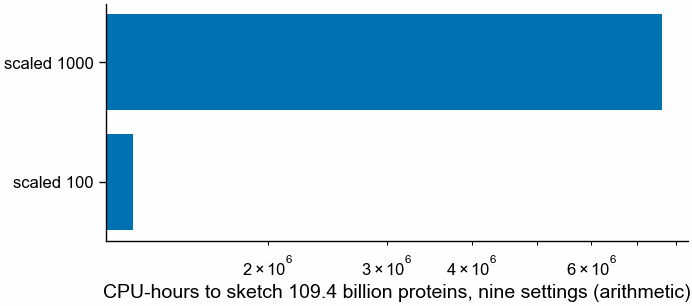

In [6]:
logan_path = DATA / "step5_logan_arithmetic.json"
if not logan_path.exists() and (DATA / "step5_run1_logan_arithmetic.json").exists():
    print(
        "From step 1 run 1, whose scaled 1000 times are lower bounds inflated by the .zip writer:"
    )
    logan_path = DATA / "step5_run1_logan_arithmetic.json"
if not logan_path.exists():
    print("Step 5 waits on step 1: no", logan_path.name)
else:
    logan = json.loads(logan_path.read_text())
    t = pl.DataFrame(logan["per_scaled"])
    print(t)
    pf.use_style()
    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 40)
    ax.barh(
        [f"scaled {s}" for s in t["scaled"]],
        t["logan_cpu_hours_arithmetic"],
        color=pf.OKABE_ITO["blue"],
    )
    ax.set_xscale("log")
    ax.set_xlabel(
        "CPU-hours to sketch 109.4 billion proteins, nine settings (arithmetic)"
    )
    pf.save(fig, str(FIGURES / "299_logan_cpu_hours_arithmetic"))

## 6. Who would use it, if step 3 passes

Named only where a page read on 2026-10-18 puts the person in the role.

- sourmash and Branchwater: **C. Titus Brown**, listed on the sourmash team on the
  Branchwater contact page; Branchwater is credited to the UC Davis Data Intensive Biology
  lab, USDA-ARS and JGI. Olga is herself an author of the Branchwater plugin.
- Logan: **Rayan Chikhi**, "Lead" on the Logan GitHub page (co-lead Artem Babaian, University
  of Toronto).
- A company that mines environmental DNA for enzymes: **Basecamp Research** (London), whose
  CEO and co-founder is Glen Gowers per its June 2025 announcement.

## 7. Second check by an agent that has not seen this work

Part of the deliverable. Once steps 2 and 3 have run, a separate agent recomputes recall and
the shuffled-hit rate for every setting from the raw tables only (DIAMOND `hits.tsv`, each
setting's `recall.pairs.tsv`, `full.counts.tsv` or `sample.counts.tsv`, `status.json`,
`queries.tsv`, `catalog_stats.json`), following `notebooks/299_data/second_agent_check.md`,
and writes a held/failed table to `notebooks/299_data/second_agent_check.csv`.

In [7]:
check_path = DATA / "second_agent_check.csv"
if not check_path.exists():
    print("Second check not run yet: it needs steps 2 and 3")
else:
    check = pl.read_csv(check_path)
    print(check)

Second check not run yet: it needs steps 2 and 3


## Summary and conclusions

**Result on 2026-10-20: step 1 run 1 says dead, but that verdict measures sourmash's `.zip`
writer, not the cost of sketching.** Under the rule as run, the catalog fits at neither
scaled value: at scaled 1000 the nine settings' lower bounds reach 3_260 CPU-hours, and at
scaled 100 the total is at least 541 with one setting unknown. Ten settings were slowed by
the `.zip` writer's handling of identical (mostly empty) sketches; written as `.sig.gz` the
same work took 2.5 s instead of 132 s on 20_000 genes. Step 1 run 2 keeps the rule and
budget and times `.sig.gz` plus a `.zip` of the non-empty sketches. Steps 2 to 4 have not run.

- Queries: 100 random arctic clam proteins (seed 299) and 9 BHF regions copied from PR 80,
  with 2_180 dipeptide-shuffled copies.
- OM-RGC v2 as published (BioStudies S-BSST297) has no protein file. The catalog is taken
  from the gene table `OM-RGC_v2.tsv.gz` (10.3 GB, DNA in column 14), which passed gzip's
  full check; two downloads of the 29.6 GB `OM-RGC_v2_genes.fna.gz` differed from each
  other. The gene count is to be read on Sherlock.
- A laptop test on the catalog's first 39_000 genes found that hp at k = 10 and scaled 100
  matches almost every query to almost every gene (52.7 million hit rows), so step 3 counts
  such settings on a 1% gene sample.

**Budget.** "Two compute days" means two days of a 32-CPU node, 1_536 CPU-hours (Olga,
2026-10-19, before the step 1 job ran).